# Satellite collision avoidance: exploratory data analysis

**Purpose:** understand telemetry quality, event histories, class imbalance, and leakage risks before training a model. This notebook analyzes the **12 permitted predictors**, with `event_id` as metadata and `risk` as the training target. Other columns are inventoried only.

**Read this first**
- `risk` is `log10(Pc)`: −6 means one in a million; −4 means one in ten thousand. Pc is collision probability, not model confidence.
- Rows are conjunction data messages (CDMs); multiple rows can update the same encounter. They are not independent samples.
- Reserve training events into 70/15/15 partitions **before detailed analysis**. Use only the 70% partition for label relationships and example histories. Test labels are never loaded.
- Earlier repository inspection already exposed aggregate full-training counts/ranges. This is disclosed; the reserved partitions have not been used here for feature–target exploration or model selection.
- No model is trained, no missing values are imputed, and no rows are silently cleaned. Raw CSV files stay unchanged.

## Contents
1. Setup, provenance, schema, and units
2. Eligibility and frozen event split
3. Data quality and distributions
4. Risk tiers and telemetry relationships
5. Event histories and timing
6. Test feature shift and overlap audit
7. Findings, reproducibility checks, and modeling handoff

Run **Restart Kernel → Run All**. Expected runtime on a typical laptop: roughly 1–3 minutes; the first plotting/font-cache initialization may take longer. The summary and split artifacts are generated locally.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split

# Find data from either the repository root or notebooks/ working directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/train_data.csv').is_file()
             and (p / 'data/test_data.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch from the repository or its notebooks directory; put both CSV files in data/.')
ARTIFACTS = ROOT / 'artifacts'
REPORTS = ROOT / 'reports'
ARTIFACTS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
SEED = 42
FEATURES = ['time_to_tca', 'miss_distance', 'relative_speed',
            'relative_position_r', 'relative_position_t', 'relative_position_n',
            'c_object_type', 'c_sigma_r', 't_sigma_r', 'max_risk_estimate', 'F10', 'AP']
NUMERIC = [c for c in FEATURES if c != 'c_object_type']
ALLOWED = ['event_id', *FEATURES]
UNITS = {'event_id': 'source-local identifier', 'time_to_tca': 'days',
         'miss_distance': 'm', 'relative_speed': 'm/s',
         'relative_position_r': 'm (radial)', 'relative_position_t': 'm (along-track)',
         'relative_position_n': 'm (cross-track)', 'c_object_type': 'category',
         'c_sigma_r': 'm', 't_sigma_r': 'm',
         'max_risk_estimate': 'supplied encoding; verify before interpreting as Pc',
         'F10': '10^-22 W / (m² Hz)', 'AP': 'geomagnetic index', 'risk': 'log10(Pc)'}
VERSIONS = {p: importlib.metadata.version(p) for p in
            ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'nbformat', 'nbclient']}
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 130, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
print('Python:', platform.python_version(), '| seed:', SEED)
display(pd.Series(VERSIONS, name='version').to_frame())

Matplotlib is building the font cache; this may take a moment.


Python: 3.13.6 | seed: 42


,version
pandas,2.2.2
numpy,2.2.2
matplotlib,3.10.1
seaborn,0.13.2
scikit-learn,1.9.1
nbformat,5.10.4
nbclient,0.10.2


## 1. Provenance, schema, and units

Load test telemetry with `usecols` so its `risk` values never enter a dataframe. File fingerprints read raw bytes solely for provenance. The complete header inventory is not a license to use excluded columns.

The [ESA data dictionary](https://kelvins.esa.int/collision-avoidance-challenge/data/) specifies days, metres, and metres/second for the corresponding telemetry. `max_risk_estimate` has negative values in the local data; its encoding must be confirmed before presenting it as a probability. Preserve it as supplied during EDA.

In [2]:
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

PATHS = {name: ROOT / 'data' / f'{name}_data.csv' for name in ['train', 'test']}
HEADERS = {name: pd.read_csv(path, nrows=0).columns.tolist() for name, path in PATHS.items()}
for name, header in HEADERS.items():
    required = set(ALLOWED + (['risk'] if name == 'train' else []))
    if not required.issubset(header):
        raise ValueError(f'{name} missing required columns: {sorted(required - set(header))}')

train_raw = pd.read_csv(PATHS['train'], usecols=ALLOWED + ['risk'])
test = pd.read_csv(PATHS['test'], usecols=ALLOWED)
assert 'risk' not in test.columns
for name, frame in [('train', train_raw), ('test', test)]:
    if frame['event_id'].isna().any():
        raise ValueError(f'{name}: missing event IDs must be resolved before splitting.')
    frame['row_id'] = np.arange(len(frame))
    frame['source'] = name
    frame['event_key'] = name + ':' + frame['event_id'].astype(str)

HASHES = {name: file_sha256(path) for name, path in PATHS.items()}
provenance = pd.DataFrame([
    {'source': name, 'rows': len(frame), 'events': frame.event_id.nunique(),
     'available_columns': len(HEADERS[name]), 'loaded_predictors': len(FEATURES),
     'size_MiB': round(PATHS[name].stat().st_size / 2**20, 2), 'sha256': HASHES[name]}
    for name, frame in [('train', train_raw), ('test', test)]])
display(provenance)
schema = pd.DataFrame({'column': HEADERS['train']})
schema['role'] = schema.column.map(lambda c: 'key' if c == 'event_id' else
                                  'training target ONLY' if c == 'risk' else
                                  'permitted predictor' if c in FEATURES else 'excluded')
schema['in_test_header'] = schema.column.isin(HEADERS['test'])
with pd.option_context('display.max_rows', 110):
    display(schema)
display(pd.Series(UNITS, name='unit / interpretation').rename_axis('column').to_frame())

,source,rows,events,available_columns,loaded_predictors,size_MiB,sha256
0,train,162634,13154,103,12,222.78,ba47ce80580d5d6ff523ddc1d724901dbdfb3a5afdc5e7...
1,test,24484,2167,103,12,33.67,fc4110e979e7d569cb8aa819d450d29311e799115b2fe5...


,column,role,in_test_header
0,event_id,key,True
1,time_to_tca,permitted predictor,True
2,mission_id,excluded,True
3,risk,training target ONLY,True
4,max_risk_estimate,permitted predictor,True
5,max_risk_scaling,excluded,True
6,miss_distance,permitted predictor,True
7,relative_speed,permitted predictor,True
8,relative_position_r,permitted predictor,True
9,relative_position_t,permitted predictor,True


,unit / interpretation
column,
event_id,source-local identifier
time_to_tca,days
miss_distance,m
relative_speed,m/s
relative_position_r,m (radial)
relative_position_t,m (along-track)
relative_position_n,m (cross-track)
c_object_type,category
c_sigma_r,m


## 2. Eligibility and a frozen event split

Prospective analysis excludes messages after TCA and invalid targets, but retains their **exclusion counts**. A valid target is finite and no greater than zero (`Pc <= 1`); the observed −30 floor is not a universal physical lower bound.

Stratify events by whether **any eligible message** has `risk >= -4`. Target use here is limited to partition balancing. Validation and holdout counts are structural checks, not an invitation to inspect their outcomes. If a future dataset cannot support stratification, stop and review rather than silently change the method.

The split CSV and manifest must both exist or both be absent. On reruns, input fingerprints, split settings, assignment contents, and the saved split hash must agree. No automatic overwriting of an incompatible split.

In [3]:
valid_time = np.isfinite(train_raw.time_to_tca) & train_raw.time_to_tca.ge(0)
valid_target = np.isfinite(train_raw.risk) & train_raw.risk.le(0)
eligible = train_raw.loc[valid_time & valid_target].copy()
eligibility = pd.Series({
    'all training rows': len(train_raw),
    'negative TCA rows': int(train_raw.time_to_tca.lt(0).sum()),
    'missing/nonfinite TCA rows': int((~np.isfinite(train_raw.time_to_tca)).sum()),
    'invalid target rows': int((~valid_target).sum()),
    'eligible prospective rows': len(eligible),
    'events with no eligible rows': train_raw.event_id.nunique() - eligible.event_id.nunique(),
}, name='count')
display(eligibility.to_frame())
event_strata = eligible.groupby('event_id', sort=True).risk.max().ge(-4).astype(int)
if event_strata.value_counts().min() < 7:
    raise ValueError('Too few events in a stratum for the planned split; review explicitly.')
train_ids, remaining_ids = train_test_split(event_strata.index.to_numpy(), test_size=0.30,
    random_state=SEED, stratify=event_strata.to_numpy())
validation_ids, holdout_ids = train_test_split(remaining_ids, test_size=0.50,
    random_state=SEED, stratify=event_strata.loc[remaining_ids].to_numpy())
expected_splits = pd.concat([
    pd.DataFrame({'event_id': ids, 'partition': name})
    for name, ids in [('train', train_ids), ('validation', validation_ids), ('holdout', holdout_ids)]
], ignore_index=True).sort_values('event_id').reset_index(drop=True)
SPLIT_PATH = ARTIFACTS / 'event_splits.csv'
MANIFEST_PATH = ARTIFACTS / 'eda_manifest.json'
settings = {'train_sha256': HASHES['train'], 'test_sha256': HASHES['test'],
            'seed': SEED, 'fractions': [0.70, 0.15, 0.15],
            'eligibility': 'finite time_to_tca >= 0; finite risk <= 0',
            'stratum': 'any eligible message risk >= -4',
            'features': FEATURES, 'sklearn_version': VERSIONS['scikit-learn']}
if SPLIT_PATH.exists() != MANIFEST_PATH.exists():
    raise RuntimeError('Incomplete split artifacts. Inspect and archive the partial artifacts before rerunning.')
if SPLIT_PATH.exists():
    manifest = json.loads(MANIFEST_PATH.read_text())
    if manifest['split_settings'] != settings:
        raise RuntimeError('Inputs/settings changed. Preserve old artifacts and deliberately create a new split.')
    splits = pd.read_csv(SPLIT_PATH).sort_values('event_id').reset_index(drop=True)
    pd.testing.assert_frame_equal(splits, expected_splits)
    assert file_sha256(SPLIT_PATH) == manifest['split_sha256'], 'Split file was modified.'
    print('Reused verified event split.')
else:
    splits = expected_splits
    splits.to_csv(SPLIT_PATH, index=False)
    manifest = {'split_settings': settings, 'split_sha256': file_sha256(SPLIT_PATH),
                'versions': VERSIONS, 'python': platform.python_version(), 'units': UNITS}
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=2) + '\n')
    print('Created frozen event split.')
assert splits.event_id.is_unique
assert set(splits.event_id) == set(eligible.event_id)
partitions = {name: set(splits.loc[splits.partition.eq(name), 'event_id'])
              for name in ['train', 'validation', 'holdout']}
assert not (partitions['train'] & partitions['validation'] or partitions['train'] & partitions['holdout']
            or partitions['validation'] & partitions['holdout'])
split_sizes = splits.groupby('partition').size().rename('events').to_frame()
split_sizes['event_percent'] = 100 * split_sizes.events / len(splits)
split_sizes['eligible_rows'] = splits.merge(eligible.groupby('event_id').size().rename('rows'),
    on='event_id').groupby('partition').rows.sum()
display(split_sizes.loc[['train', 'validation', 'holdout']])
eda = eligible.loc[eligible.event_id.isin(partitions['train'])].copy()
assert set(eda.event_id) == partitions['train']
# Delete label-bearing full/held-out frames after the split. Keep all-training telemetry for overlap checks only.
train_telemetry = train_raw[ALLOWED + ['row_id', 'source', 'event_key']].copy()
del train_raw, eligible, event_strata, valid_target, valid_time
print(f'Detailed EDA uses {len(eda):,} rows from {eda.event_id.nunique():,} training-partition events only.')

,count
all training rows,162634
negative TCA rows,391
missing/nonfinite TCA rows,0
invalid target rows,0
eligible prospective rows,162243
events with no eligible rows,11


Created frozen event split.


,events,event_percent,eligible_rows
partition,,,
train,9200,69.999239,113195
validation,1971,14.996576,24359
holdout,1972,15.004185,24689


Detailed EDA uses 113,195 rows from 9,200 training-partition events only.


## 3. Data quality

All tables in this section use the **training partition**. Missingness, infinities, negative physical quantities, duplicate telemetry, and tied updates are different issues. Report them separately; do not drop rows merely because telemetry repeats across messages.

,dtype,missing,missing_pct,unique_nonmissing,infinite,invalid_negative
time_to_tca,float64,0,0.000000,113123,0,NaN
miss_distance,float64,0,0.000000,41104,0,0.0
relative_speed,float64,0,0.000000,6928,0,0.0
relative_position_r,float64,0,0.000000,27934,0,NaN
relative_position_t,float64,0,0.000000,95117,0,NaN
relative_position_n,float64,0,0.000000,98961,0,NaN
c_object_type,object,0,0.000000,5,0,NaN
c_sigma_r,float64,8,0.007067,111235,0,0.0
t_sigma_r,float64,0,0.000000,111246,0,0.0
max_risk_estimate,float64,0,0.000000,33342,0,NaN


,count,mean,std,min,1%,5%,50%,95%,99%,max
time_to_tca,113195.0,3.356099,2.009727e+00,0.000057,0.064077,0.309207,3.302244,6.555306,6.865308e+00,6.993044e+00
miss_distance,113195.0,16494.280913,1.428979e+04,16.000000,252.000000,769.000000,12343.000000,45601.300000,5.574124e+04,6.737300e+04
relative_speed,113195.0,10653.644401,4.336298e+03,16.000000,218.000000,2254.000000,12266.000000,15034.000000,1.521000e+04,1.713800e+04
relative_position_r,113195.0,-32.906444,6.494898e+02,-4675.700000,-1838.618000,-1222.430000,-26.600000,1163.250000,1.790112e+03,5.284100e+03
relative_position_t,113195.0,-144.575918,1.487391e+04,-62184.200000,-40846.556000,-26553.790000,-17.800000,26796.000000,4.104923e+04,6.218430e+04
relative_position_n,113195.0,177.846580,1.595523e+04,-50988.600000,-44348.420000,-27887.490000,53.700000,28329.930000,4.354652e+04,5.098870e+04
c_sigma_r,113187.0,966255.269388,7.789089e+06,0.940607,3.034382,7.758790,69.125162,1074.068289,6.378136e+07,6.378136e+07
t_sigma_r,113195.0,951697.904400,7.732721e+06,0.699496,1.212987,1.623112,4.739153,16.360584,6.378136e+07,6.378136e+07
max_risk_estimate,113195.0,-6.275041,1.013108e+00,-9.814175,-8.397404,-7.845363,-6.323306,-4.527639,-3.748819e+00,-1.082442e+00
F10,108596.0,77.966454,1.464117e+01,66.000000,67.000000,67.000000,72.000000,110.000000,1.360000e+02,2.460000e+02


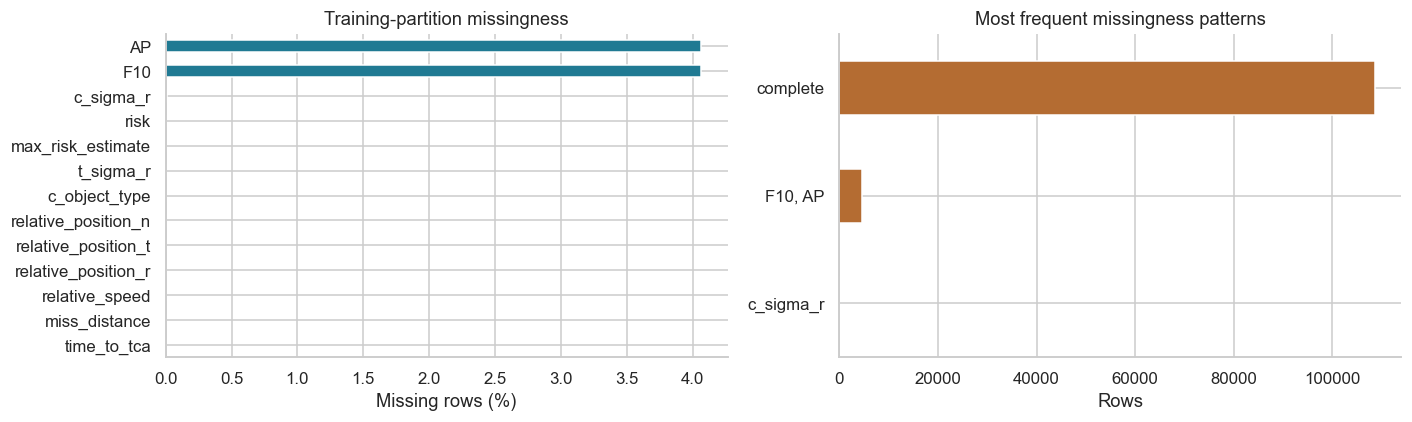

,rows
extra identical event + telemetry + target rows,0
extra identical telemetry rows (ID/target excluded),0
extra tied event/time rows,0
rows participating in an event/time tie,0


In [4]:
NONNEGATIVE = ['miss_distance', 'relative_speed', 'c_sigma_r', 't_sigma_r', 'F10', 'AP']
quality = pd.DataFrame(index=FEATURES + ['risk'])
quality['dtype'] = eda[quality.index].dtypes.astype(str)
quality['missing'] = eda[quality.index].isna().sum()
quality['missing_pct'] = 100 * quality.missing / len(eda)
quality['unique_nonmissing'] = eda[quality.index].nunique()
quality['infinite'] = 0
quality.loc[NUMERIC + ['risk'], 'infinite'] = np.isinf(eda[NUMERIC + ['risk']]).sum()
quality['invalid_negative'] = pd.Series({c: int(eda[c].lt(0).sum()) for c in NONNEGATIVE})
display(quality)
display(eda[NUMERIC + ['risk']].describe(percentiles=[.01, .05, .5, .95, .99]).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
quality.missing_pct.sort_values().plot.barh(ax=axes[0], color='#207a93')
axes[0].set(xlabel='Missing rows (%)', title='Training-partition missingness')
missing_patterns = eda[FEATURES].isna().apply(
    lambda row: ', '.join(row.index[row]) or 'complete', axis=1).value_counts().head(8)
missing_patterns.sort_values().plot.barh(ax=axes[1], color='#b46c32')
axes[1].set(xlabel='Rows', title='Most frequent missingness patterns')
fig.tight_layout(); plt.show()

duplicate_summary = pd.Series({
    'extra identical event + telemetry + target rows': int(eda.duplicated(['event_id', *FEATURES, 'risk']).sum()),
    'extra identical telemetry rows (ID/target excluded)': int(eda.duplicated(FEATURES).sum()),
    'extra tied event/time rows': int(eda.duplicated(['event_id', 'time_to_tca']).sum()),
    'rows participating in an event/time tie': int(eda.duplicated(['event_id', 'time_to_tca'], keep=False).sum()),
}, name='rows')
display(duplicate_summary.to_frame())

### Extreme uncertainty and geometry consistency

A large repeated sigma may be a sentinel, a real failed orbit estimate, or another data-processing effect. A plot cannot establish which. The 99.9th percentile below is a **descriptive flag**, not a cleaning threshold fitted for future modeling.

The norm of R/T/N relative position should be broadly consistent with miss distance if both fields use the same encounter geometry. Rounding or differing calculations can create small differences; this diagnostic does not validate physical Pc.

c_sigma_r — most frequent values:


,rows
c_sigma_r,
6.378136e+07,1317
6.378136e+07,397
3.269529e+01,4
3.280409e+01,3
3.497405e+01,3


t_sigma_r — most frequent values:


,rows
t_sigma_r,
6.378136e+07,1093
6.378136e+07,596
4.031191e+00,3
3.257177e+00,3
3.670000e+00,2


,feature,p99,p999,maximum_m,rows_at_maximum,rows_over_1000000_m
0,c_sigma_r,6.378136e+07,63781363.0,63781363.0,397,1714
1,t_sigma_r,6.378136e+07,63781363.0,63781363.0,1093,1689


,absolute difference (m)
count,113195.000000
mean,0.501675
std,0.289647
min,0.000004
50%,0.502189
95%,0.951212
99%,1.005801
max,1.056909


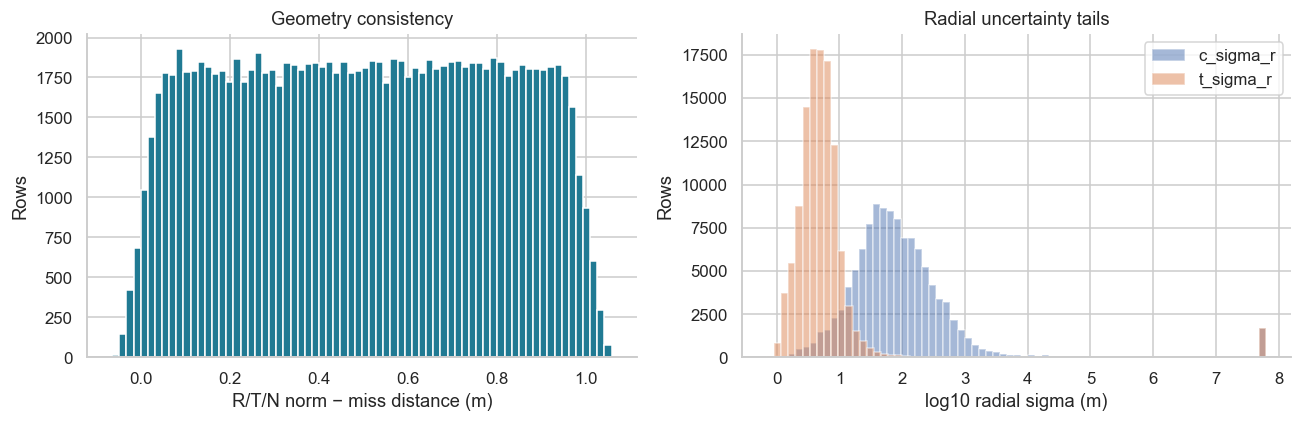

In [5]:
sigma_audit = []
for col in ['c_sigma_r', 't_sigma_r']:
    values = eda[col].replace([np.inf, -np.inf], np.nan)
    maximum = values.max()
    sigma_audit.append({'feature': col, 'p99': values.quantile(.99), 'p999': values.quantile(.999),
                        'maximum_m': maximum, 'rows_at_maximum': int(values.eq(maximum).sum()),
                        'rows_over_1000000_m': int(values.gt(1_000_000).sum())})
    print(col, '— most frequent values:')
    display(values.value_counts().head(5).rename('rows').to_frame())
sigma_audit = pd.DataFrame(sigma_audit)
display(sigma_audit)
position_norm = np.sqrt(eda[['relative_position_r', 'relative_position_t', 'relative_position_n']].pow(2).sum(axis=1, min_count=3))
geometry_error = position_norm - eda.miss_distance
geometry_summary = geometry_error.abs().describe(percentiles=[.5, .95, .99]).rename('absolute difference (m)')
display(geometry_summary.to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(geometry_error.dropna(), bins=70, color='#207a93')
axes[0].set(xlabel='R/T/N norm − miss distance (m)', ylabel='Rows', title='Geometry consistency')
for col in ['c_sigma_r', 't_sigma_r']:
    values = eda.loc[eda[col].gt(0) & np.isfinite(eda[col]), col]
    axes[1].hist(np.log10(values), bins=70, alpha=.5, label=col)
axes[1].legend(); axes[1].set(xlabel='log10 radial sigma (m)', ylabel='Rows', title='Radial uncertainty tails')
fig.tight_layout(); plt.show()

### Univariate distributions

Positive skewed features use log-scaled axes, not modified stored values. Signed relative positions retain their signs with a symmetric log scale. Bars and summaries use the full analysis partition; scatterplots later use a seeded sample.

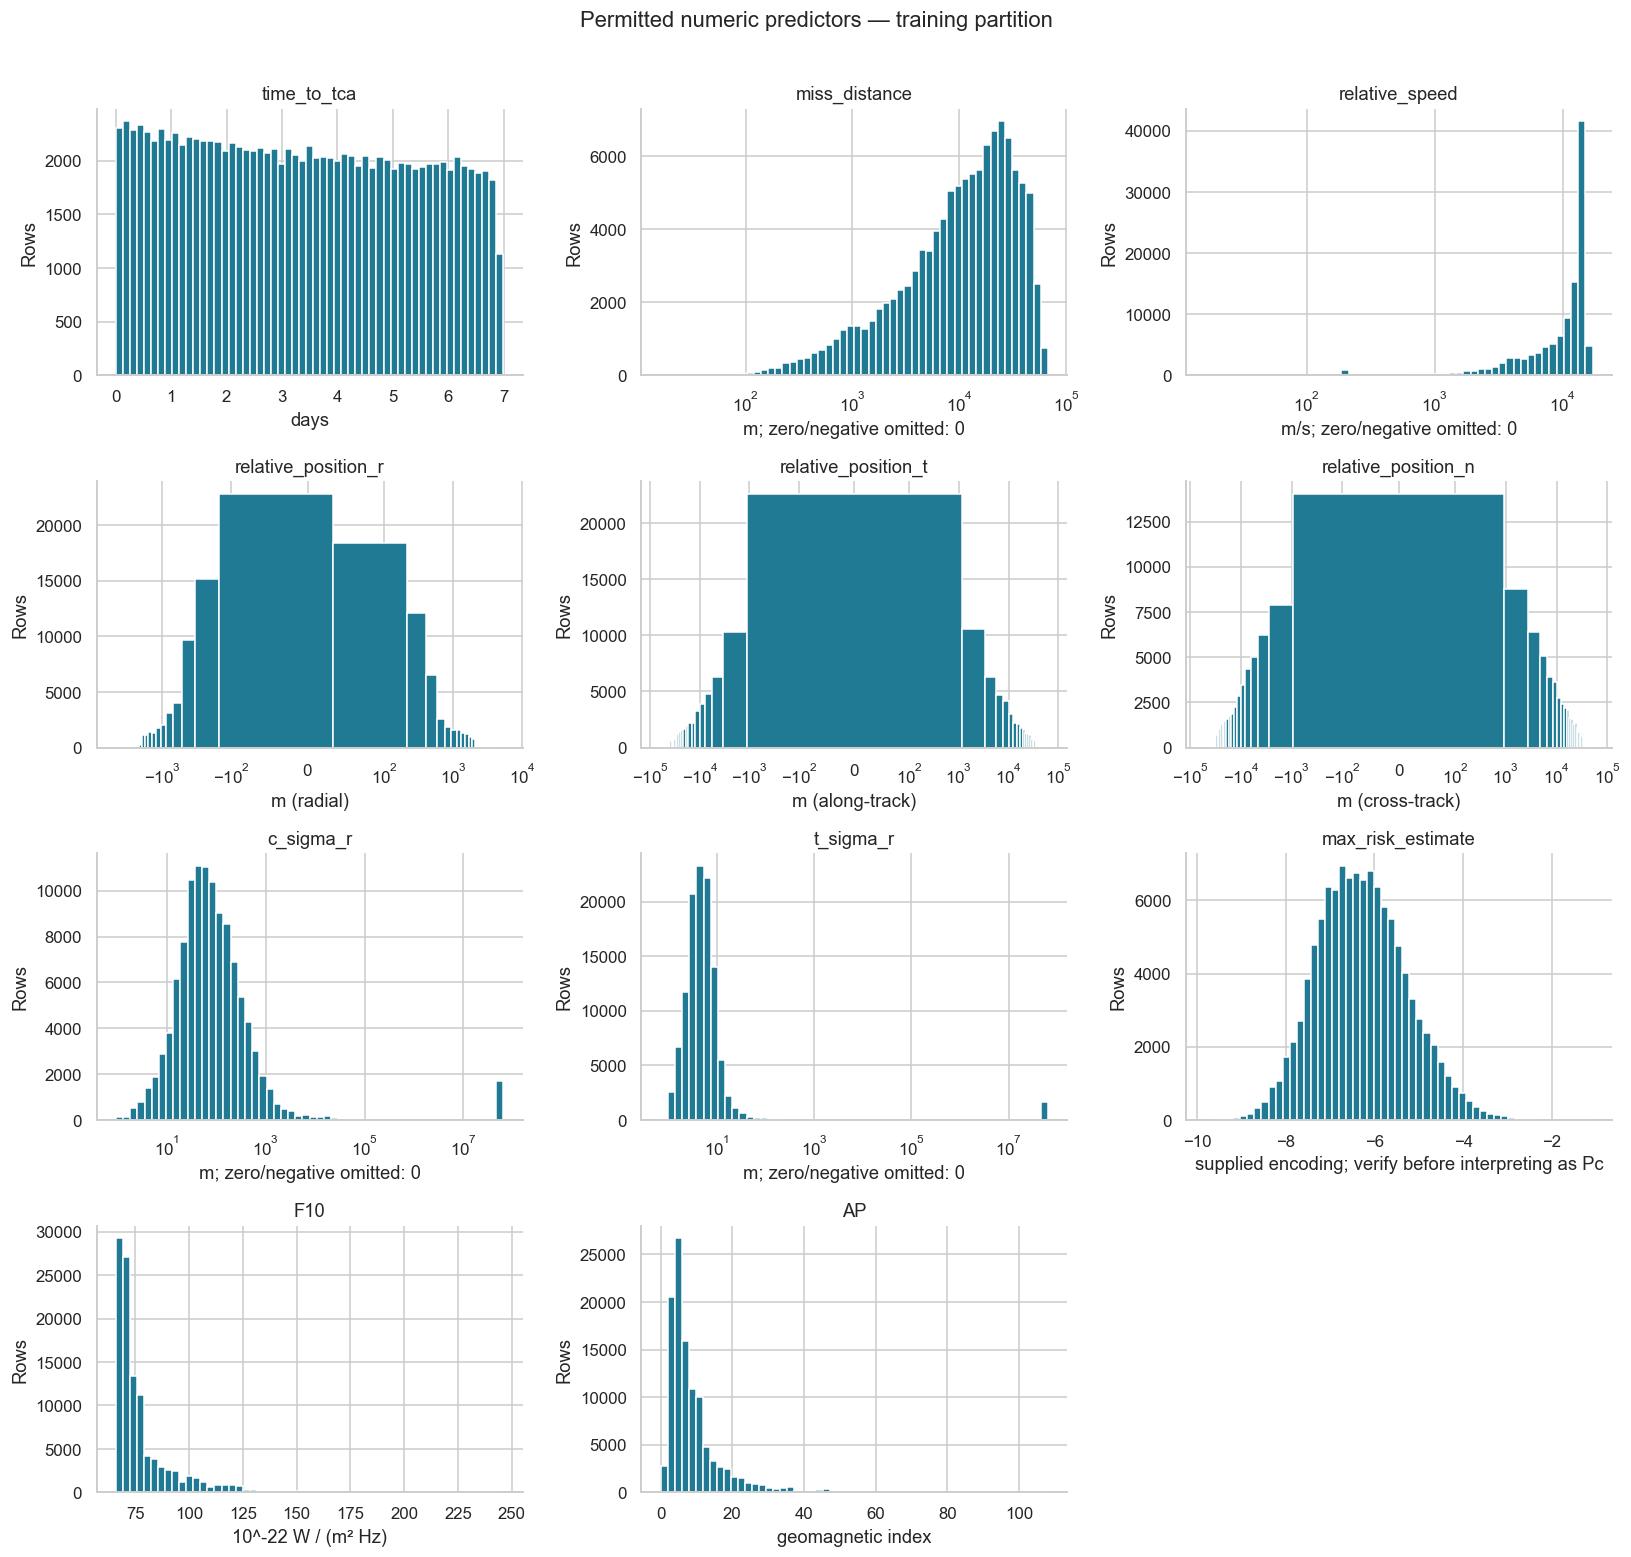

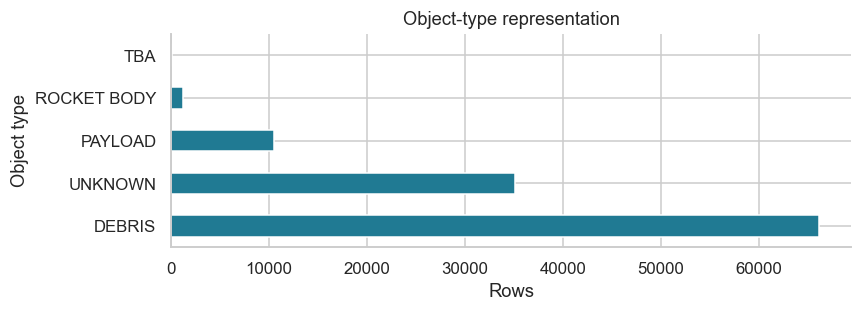

,rows
c_object_type,
DEBRIS,66109
UNKNOWN,35145
PAYLOAD,10544
ROCKET BODY,1269
TBA,128


In [6]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, col in zip(axes.flat, NUMERIC):
    values = eda.loc[np.isfinite(eda[col]), col]
    if col in ['miss_distance', 'relative_speed', 'c_sigma_r', 't_sigma_r'] and values.gt(0).any():
        positive = values[values.gt(0)]
        lo, hi = positive.min(), positive.max()
        bins = np.geomspace(lo, hi, 55) if hi > lo else 10
        ax.hist(positive, bins=bins, color='#207a93'); ax.set_xscale('log')
        suffix = f'; zero/negative omitted: {int(values.le(0).sum())}'
    else:
        ax.hist(values, bins=55, color='#207a93'); suffix = ''
        if col.startswith('relative_position_'):
            ax.set_xscale('symlog', linthresh=100)
    ax.set(title=col, xlabel=UNITS[col] + suffix, ylabel='Rows')
axes.flat[-1].axis('off')
fig.suptitle('Permitted numeric predictors — training partition', y=1.01)
fig.tight_layout(); plt.show()
object_counts = eda.c_object_type.fillna('(missing)').value_counts()
fig, ax = plt.subplots(figsize=(8, 3))
object_counts.plot.barh(ax=ax, color='#207a93')
ax.set(xlabel='Rows', ylabel='Object type', title='Object-type representation')
fig.tight_layout(); plt.show()
display(object_counts.rename('rows').to_frame())

## 4. Target and operational risk tiers

Apply the hackathon policy in priority order:

| Tier | Condition |
|---|---|
| Critical | `risk >= -4` **or** miss distance `< 1000 m` |
| Elevated | Not critical, and `risk >= -6` **or** distance `<= 5000 m` |
| Safe | `risk < -6` **and** distance `> 5000 m` |

Exactly 1 km or 5 km is elevated by distance; exactly −4 is critical and exactly −6 is elevated by Pc. Unknown/invalid inputs do not silently become safe. These are challenge policy labels, not a claim of certified NASA/ESA compliance.

Separate **Pc-only** risk from distance-triggered risk: an easy distance rule could otherwise conceal poor detection of rare high-Pc encounters.

,messages / Pc-only,messages / combined,latest event / Pc-only,latest event / combined
safe,106191,80545,8938,6879
elevated,6501,24533,252,1686
critical,503,8117,10,635
needs_review,0,0,0,0


,log10_pc,Pc
0,-30.0,1.000000e-30
1,-6.0,1.000000e-06
2,-4.0,1.000000e-04
3,-2.0,1.000000e-02


Observed −30 floor: 46,702 / 113,195 analysis rows (41.26%).


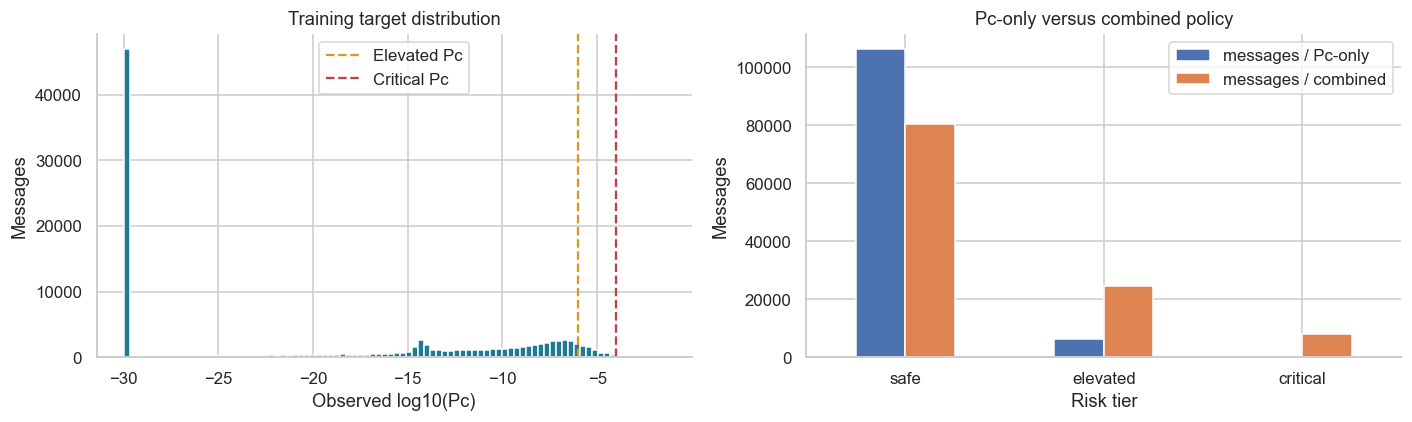

,messages
Pc only,242
distance only,7614
both,261
neither,105078


risk_tier,safe,elevated,critical,needs_review
pc_tier,,,,
safe,80545,19357,6289,0
elevated,0,5176,1325,0
critical,0,0,503,0
needs_review,0,0,0,0


In [7]:
TIER_ORDER = ['safe', 'elevated', 'critical', 'needs_review']
TIER_COLORS = {'safe': '#238b65', 'elevated': '#d79b24', 'critical': '#bf4145', 'needs_review': '#737b83'}
def risk_tier(log_pc, distance):
    p = np.asarray(log_pc, dtype=float)
    d = np.asarray(distance, dtype=float)
    valid_p = np.isfinite(p) & (p <= 0)
    valid_d = np.isfinite(d) & (d >= 0)
    critical = (valid_p & (p >= -4)) | (valid_d & (d < 1000))
    both_valid = valid_p & valid_d
    return np.select([critical, both_valid & ((p >= -6) | (d <= 5000)), both_valid],
                     ['critical', 'elevated', 'safe'], default='needs_review')

def pc_tier(log_pc):
    p = np.asarray(log_pc, dtype=float)
    return np.select([~np.isfinite(p) | (p > 0), p >= -4, p >= -6],
                     ['needs_review', 'critical', 'elevated'], default='safe')

def latest_messages(frame):
    return (frame.loc[np.isfinite(frame.time_to_tca) & frame.time_to_tca.ge(0)]
            .sort_values(['event_key', 'time_to_tca', 'row_id'], ascending=[True, True, False])
            .drop_duplicates('event_key', keep='first'))

eda['pc_tier'] = pc_tier(eda.risk)
eda['risk_tier'] = risk_tier(eda.risk, eda.miss_distance)
latest = latest_messages(eda)
tier_counts = pd.concat({
    'messages / Pc-only': eda.pc_tier.value_counts(),
    'messages / combined': eda.risk_tier.value_counts(),
    'latest event / Pc-only': latest.pc_tier.value_counts(),
    'latest event / combined': latest.risk_tier.value_counts(),
}, axis=1).reindex(TIER_ORDER).fillna(0).astype(int)
display(tier_counts)
probability_examples = pd.DataFrame({'log10_pc': [-30., -6., -4., -2.]})
probability_examples['Pc'] = 10.0 ** probability_examples.log10_pc
display(probability_examples)
floor_count = int(eda.risk.eq(-30).sum())
print(f'Observed −30 floor: {floor_count:,} / {len(eda):,} analysis rows ({100*floor_count/len(eda):.2f}%).')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(eda.risk, bins=90, color='#207a93')
for threshold, label in [(-6, 'Elevated Pc'), (-4, 'Critical Pc')]:
    axes[0].axvline(threshold, color=TIER_COLORS['critical' if threshold == -4 else 'elevated'], linestyle='--', label=label)
axes[0].legend(); axes[0].set(xlabel='Observed log10(Pc)', ylabel='Messages', title='Training target distribution')
tier_counts.loc[['safe', 'elevated', 'critical'], ['messages / Pc-only', 'messages / combined']].plot.bar(ax=axes[1])
axes[1].set(ylabel='Messages', xlabel='Risk tier', title='Pc-only versus combined policy')
axes[1].tick_params(axis='x', rotation=0)
fig.tight_layout(); plt.show()

pc_trigger = eda.risk.ge(-4)
distance_trigger = eda.miss_distance.ge(0) & eda.miss_distance.lt(1000)
trigger_counts = pd.Series({'Pc only': int((pc_trigger & ~distance_trigger).sum()),
                           'distance only': int((~pc_trigger & distance_trigger).sum()),
                           'both': int((pc_trigger & distance_trigger).sum()),
                           'neither': int((~pc_trigger & ~distance_trigger).sum())}, name='messages')
display(trigger_counts.to_frame())
display(pd.crosstab(eda.pc_tier, eda.risk_tier).reindex(index=TIER_ORDER, columns=TIER_ORDER, fill_value=0).fillna(0).astype(int))

### Relationships and slices

Look for nonlinearity, floor effects, confounding by uncertainty, and sparse categories. `max_risk_estimate` is already a risk-derived upstream quantity: examine its relationship and provenance, but do not assume it is a raw probability or independent information.

Use Spearman rank correlation for monotonic association. Repeated event messages can dominate both correlations and row-level plots, so the notebook also includes event-level counts. No significance or causal claim follows from these plots.

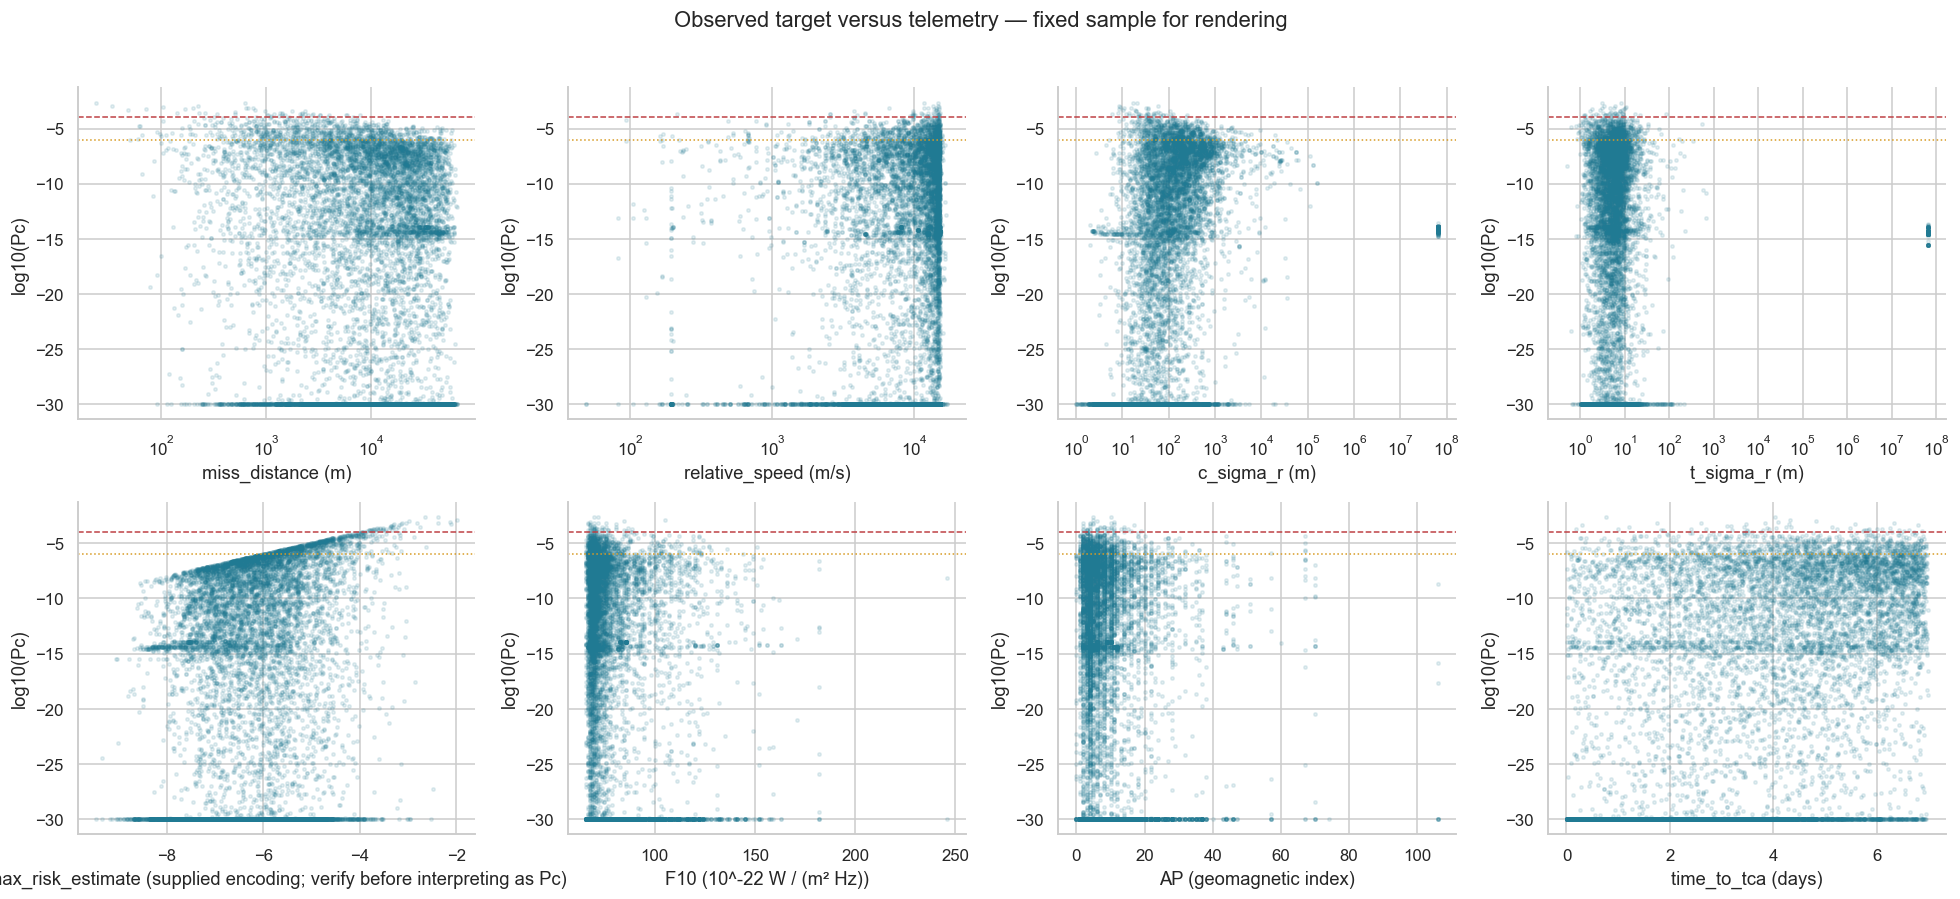

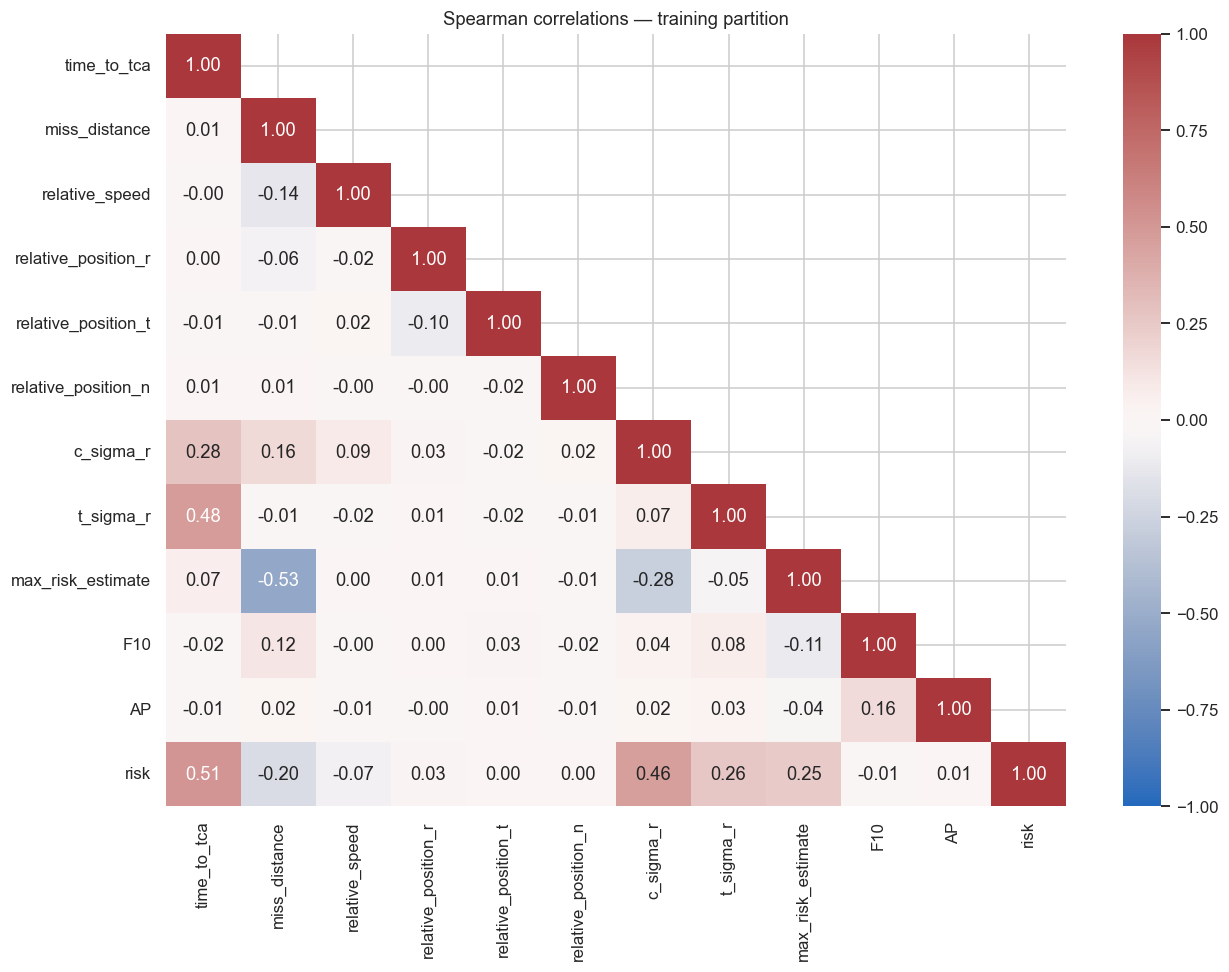

c_object_type


,slice,rows,events,median_log10_pc,Pc_critical_rows,Pc_critical_pct,combined_critical_rows
0,DEBRIS,66109,5084,-19.236347,338,0.511277,5135
1,PAYLOAD,10544,1027,-30.000000,51,0.483687,702
2,ROCKET BODY,1269,114,-30.000000,5,0.394011,242
3,TBA,128,20,-29.047588,1,0.781250,38
4,UNKNOWN,35145,2955,-13.999566,108,0.307298,2000


time_band


,slice,rows,events,median_log10_pc,Pc_critical_rows,Pc_critical_pct,combined_critical_rows
0,0–24 h,17924,6622,-30.000000,20,0.111582,1226
1,>24–48 h,17232,6452,-30.000000,27,0.156685,1187
2,>48–96 h,32621,6852,-22.539854,133,0.407713,2324
3,>96 h,45418,7304,-10.818442,323,0.711172,3380


missing_optional


,slice,rows,events,median_log10_pc,Pc_critical_rows,Pc_critical_pct,combined_critical_rows
0,False,108588,8871,-17.761327,478,0.440196,7664
1,True,4607,354,-18.639975,25,0.542652,453


,threshold,window,rows,events
0,-6,±0.5 log10 units,6371,1625
1,-4,±0.5 log10 units,1031,230


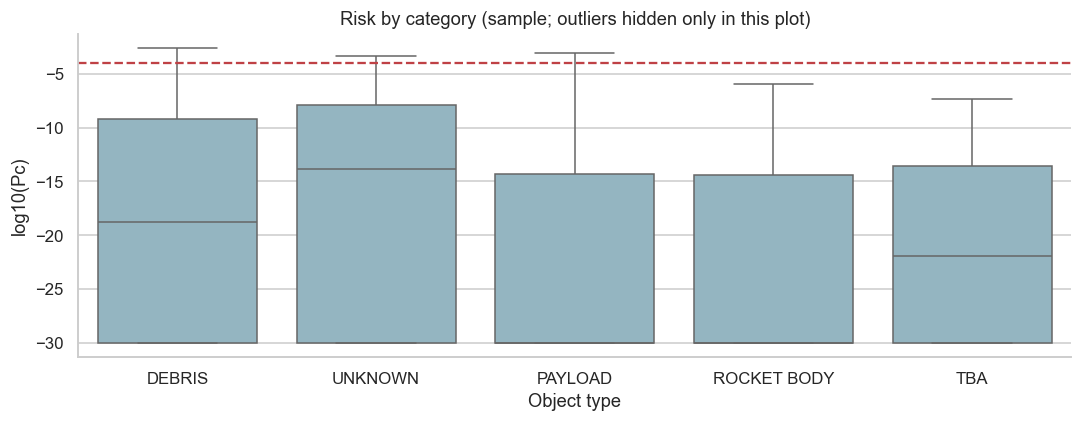

In [8]:
sample = eda.sample(n=min(12000, len(eda)), random_state=SEED)
relationship_features = ['miss_distance', 'relative_speed', 'c_sigma_r', 't_sigma_r',
                         'max_risk_estimate', 'F10', 'AP', 'time_to_tca']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, relationship_features):
    ax.scatter(sample[col], sample.risk, s=5, alpha=.12, color='#207a93', rasterized=True)
    if col in ['miss_distance', 'relative_speed', 'c_sigma_r', 't_sigma_r']:
        ax.set_xscale('symlog', linthresh=1)
    ax.axhline(-4, color='#bf4145', linestyle='--', linewidth=1)
    ax.axhline(-6, color='#d79b24', linestyle=':', linewidth=1)
    ax.set(xlabel=f'{col} ({UNITS[col]})', ylabel='log10(Pc)')
fig.suptitle('Observed target versus telemetry — fixed sample for rendering', y=1.02)
fig.tight_layout(); plt.show()
correlations = eda[NUMERIC + ['risk']].corr(method='spearman')
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(correlations, vmin=-1, vmax=1, cmap='vlag', center=0, annot=True, fmt='.2f', ax=ax,
            mask=np.triu(np.ones_like(correlations, dtype=bool), k=1))
ax.set_title('Spearman correlations — training partition'); fig.tight_layout(); plt.show()

eda['time_band'] = pd.cut(eda.time_to_tca, [-np.inf, 1, 2, 4, np.inf],
                          labels=['0–24 h', '>24–48 h', '>48–96 h', '>96 h'])
eda['missing_optional'] = eda[['c_sigma_r', 't_sigma_r', 'F10', 'AP', 'c_object_type']].isna().any(axis=1)
def slice_summary(frame, column):
    rows = []
    for key, group in frame.groupby(column, observed=True, dropna=False):
        rows.append({'slice': str(key), 'rows': len(group), 'events': group.event_id.nunique(),
                     'median_log10_pc': group.risk.median(), 'Pc_critical_rows': int(group.risk.ge(-4).sum()),
                     'Pc_critical_pct': 100 * group.risk.ge(-4).mean(),
                     'combined_critical_rows': int(group.risk_tier.eq('critical').sum())})
    return pd.DataFrame(rows)
slice_tables = {c: slice_summary(eda, c) for c in ['c_object_type', 'time_band', 'missing_optional']}
for name, table in slice_tables.items():
    print(name); display(table)
threshold_bands = pd.DataFrame([
    {'threshold': threshold, 'window': '±0.5 log10 units',
     'rows': int(eda.risk.sub(threshold).abs().le(.5).sum()),
     'events': eda.loc[eda.risk.sub(threshold).abs().le(.5), 'event_id'].nunique()}
    for threshold in [-6, -4]])
display(threshold_bands)
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=sample, x='c_object_type', y='risk', showfliers=False, color='#8db9c8', ax=ax)
ax.axhline(-4, color='#bf4145', linestyle='--')
ax.set(xlabel='Object type', ylabel='log10(Pc)', title='Risk by category (sample; outliers hidden only in this plot)')
fig.tight_layout(); plt.show()

## 5. Event histories and temporal coverage

A smaller nonnegative `time_to_tca` is a newer pre-TCA message. For tied times, choose the **last original CSV row** deterministically; this tie-breaker does not establish real observation order.

The positions are successive estimates of encounter geometry **at TCA**, not a measured flight path. The files do not provide a common wall-clock date for all events. A count of historical events with messages within 24 hours is not a forecast of a real fleet's next day.

,count
analysis events,9200
events with a message in 0–24 h,6622
latest messages in 0–24 h,6622
latest events in 0–24 h and distance <1 km,443
latest events in 0–24 h and combined-critical,445
events with at least one tier change,2499
test messages in 0–24 h,0


risk_tier,critical,elevated,safe
risk_tier,,,
critical,6464,871,147
elevated,855,20030,1962
safe,128,1627,71911


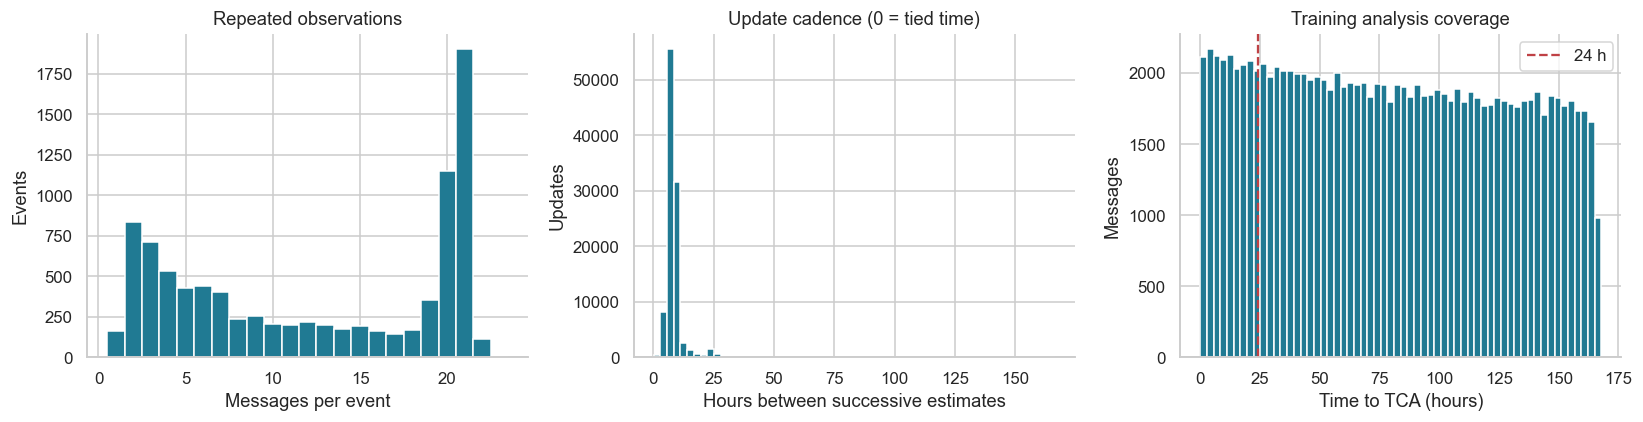

In [9]:
ordered = eda.sort_values(['event_key', 'time_to_tca', 'row_id'], ascending=[True, False, True]).copy()
message_counts = ordered.groupby('event_key').size()
ordered['update_gap_hours'] = -ordered.groupby('event_key').time_to_tca.diff() * 24
ordered['risk_change'] = ordered.groupby('event_key').risk.diff()
previous_tier = ordered.groupby('event_key').risk_tier.shift()
tier_changed = previous_tier.notna() & ordered.risk_tier.ne(previous_tier)
transition_table = pd.crosstab(previous_tier[previous_tier.notna()], ordered.loc[previous_tier.notna(), 'risk_tier'])
event_metrics = ordered.groupby('event_key').agg(event_id=('event_id', 'first'), messages=('row_id', 'size'),
    maximum_risk=('risk', 'max'), minimum_risk=('risk', 'min'),
    minimum_tca_days=('time_to_tca', 'min'), maximum_tca_days=('time_to_tca', 'max'),
    maximum_c_sigma=('c_sigma_r', 'max'))
event_metrics['largest_rise'] = ordered.groupby('event_key').risk_change.max()
event_metrics['all_safe'] = ordered.groupby('event_key').risk_tier.apply(lambda x: x.eq('safe').all())
latest = latest_messages(eda)
timing_summary = pd.Series({
    'analysis events': len(event_metrics),
    'events with a message in 0–24 h': eda.loc[eda.time_to_tca.between(0, 1), 'event_key'].nunique(),
    'latest messages in 0–24 h': int(latest.time_to_tca.between(0, 1).sum()),
    'latest events in 0–24 h and distance <1 km': int((latest.time_to_tca.between(0, 1) & latest.miss_distance.ge(0) & latest.miss_distance.lt(1000)).sum()),
    'latest events in 0–24 h and combined-critical': int((latest.time_to_tca.between(0, 1) & latest.risk_tier.eq('critical')).sum()),
    'events with at least one tier change': ordered.loc[tier_changed, 'event_key'].nunique(),
    'test messages in 0–24 h': int(test.time_to_tca.between(0, 1).sum()),
}, name='count')
display(timing_summary.to_frame()); display(transition_table)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(message_counts, bins=np.arange(.5, message_counts.max() + 1.5), color='#207a93')
axes[0].set(xlabel='Messages per event', ylabel='Events', title='Repeated observations')
axes[1].hist(ordered.update_gap_hours.dropna(), bins=60, color='#207a93')
axes[1].set(xlabel='Hours between successive estimates', ylabel='Updates', title='Update cadence (0 = tied time)')
axes[2].hist(eda.time_to_tca * 24, bins=60, color='#207a93')
axes[2].axvline(24, color='#bf4145', linestyle='--', label='24 h')
axes[2].legend(); axes[2].set(xlabel='Time to TCA (hours)', ylabel='Messages', title='Training analysis coverage')
fig.tight_layout(); plt.show()

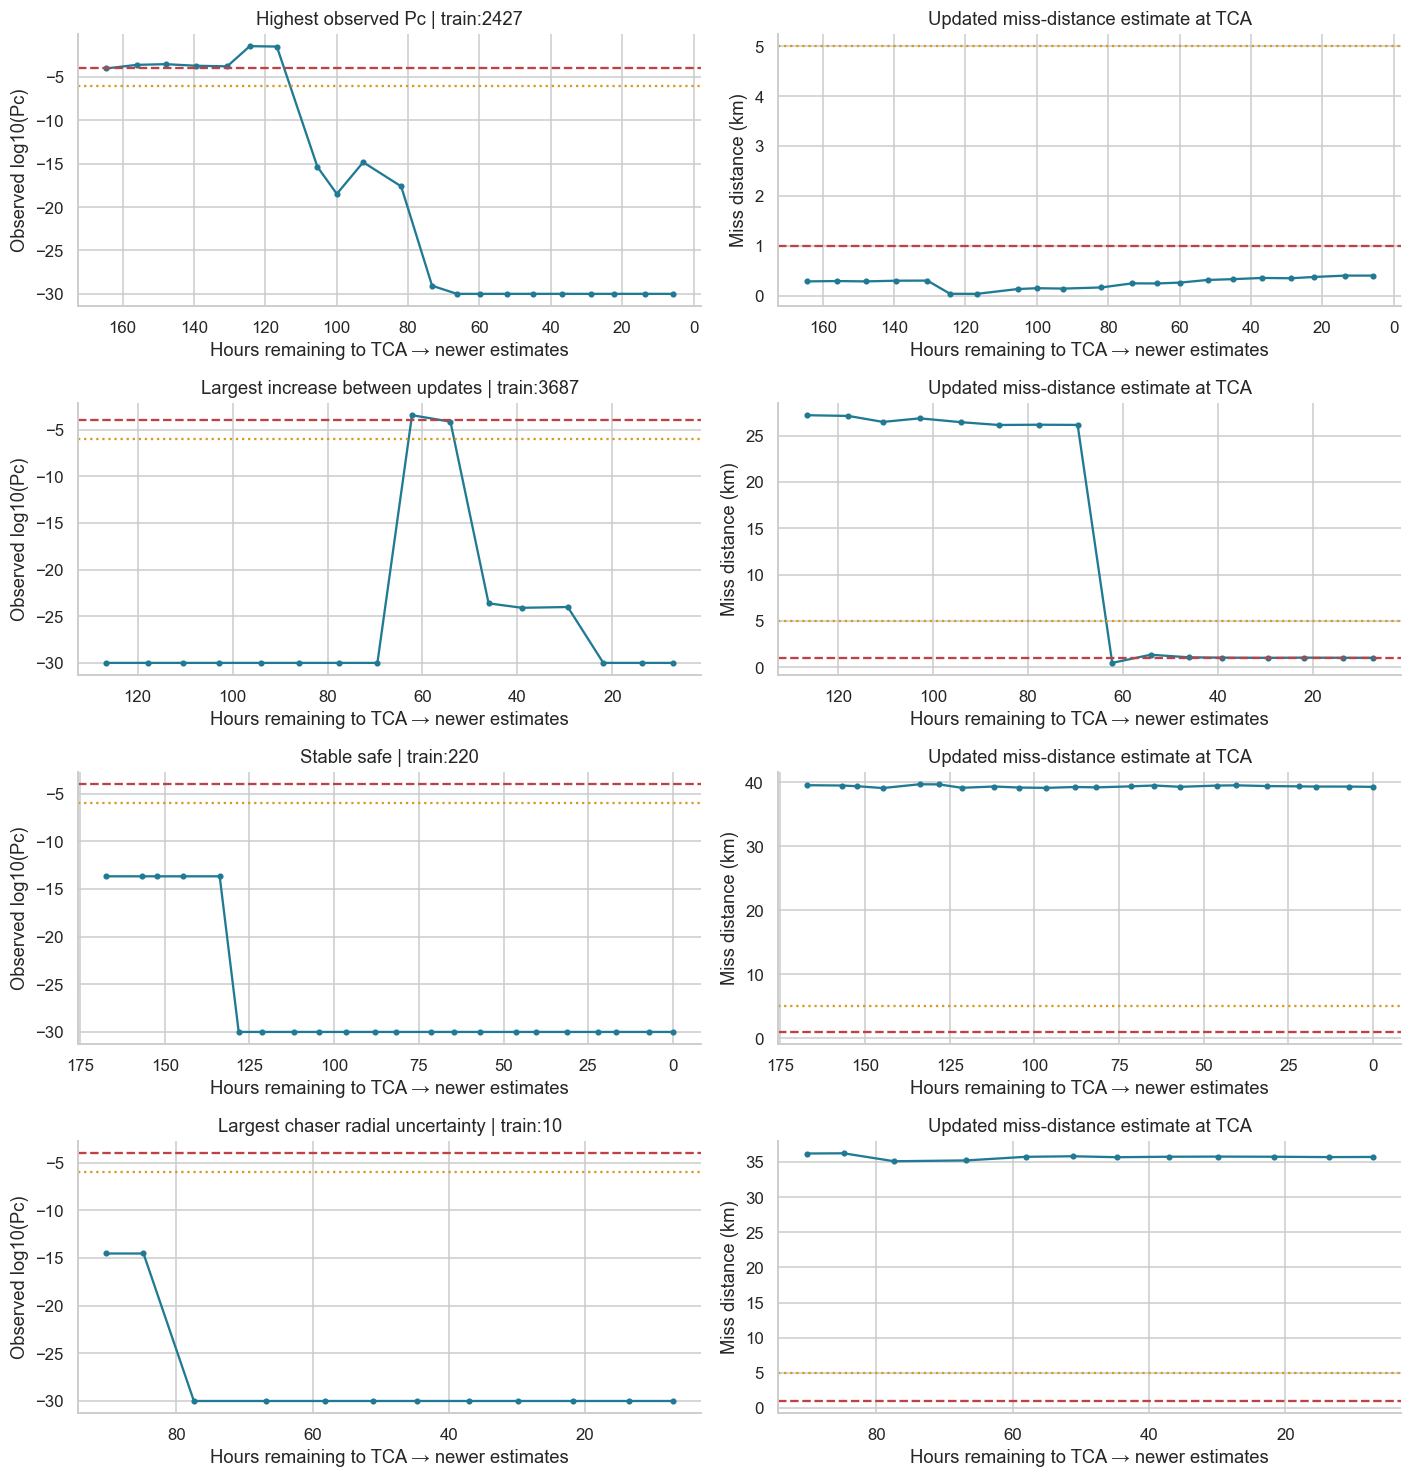

,event_id,messages,maximum_risk,minimum_risk,minimum_tca_days,maximum_tca_days,maximum_c_sigma,largest_rise,all_safe
event_key,,,,,,,,,
train:2427,2427,21,-1.442854,-30.0,0.241260,6.854137,2.520105e+01,3.650842,False
train:3687,3687,16,-3.436163,-30.0,0.302837,5.273560,7.563332e+01,26.563837,False
train:220,220,22,-13.664743,-30.0,0.001234,6.966934,4.989167e+00,0.000000,True
train:10,10,12,-14.517841,-30.0,0.297513,3.759978,6.378136e+07,0.000000,True


In [10]:
# Deterministic example selection from the training partition only; not representative samples.
candidates = event_metrics.loc[event_metrics.messages.ge(2)]
selection_specs = [
    ('Highest observed Pc', candidates, 'maximum_risk'),
    ('Largest increase between updates', candidates.loc[candidates.largest_rise.gt(0)], 'largest_rise'),
    ('Stable safe', candidates.loc[candidates.all_safe], 'messages'),
    ('Largest chaser radial uncertainty', candidates, 'maximum_c_sigma'),
]
examples = []
used = set()
for label, pool, sort_col in selection_specs:
    pool = pool.loc[~pool.index.isin(used)].sort_values([sort_col, 'event_id'], ascending=[False, True])
    if not pool.empty:
        key = pool.index[0]; used.add(key); examples.append((label, key))
if not examples:
    raise ValueError('No multi-message training events available for history plots.')
fig, axes = plt.subplots(len(examples), 2, figsize=(13, 3.4 * len(examples)), squeeze=False)
for row, (label, key) in enumerate(examples):
    history = ordered.loc[ordered.event_key.eq(key)]
    hours = history.time_to_tca * 24
    axes[row, 0].plot(hours, history.risk, marker='o', markersize=3, color='#207a93')
    axes[row, 0].axhline(-4, color='#bf4145', linestyle='--')
    axes[row, 0].axhline(-6, color='#d79b24', linestyle=':')
    axes[row, 0].set(title=f'{label} | {key}', ylabel='Observed log10(Pc)')
    axes[row, 1].plot(hours, history.miss_distance / 1000, marker='o', markersize=3, color='#207a93')
    axes[row, 1].axhline(1, color='#bf4145', linestyle='--')
    axes[row, 1].axhline(5, color='#d79b24', linestyle=':')
    axes[row, 1].set(title='Updated miss-distance estimate at TCA', ylabel='Miss distance (km)')
    for ax in axes[row]:
        ax.invert_xaxis(); ax.set_xlabel('Hours remaining to TCA → newer estimates')
fig.tight_layout(); plt.show()
display(event_metrics.loc[[key for _, key in examples]])

## 6. Test telemetry: distribution shift and possible overlap

Compare the training analysis partition with test **features only**. Differences may reflect the test selection process, its earlier time horizon, or a different event mixture. They do not tell us test accuracy. Do not tune transformations to make these distributions match.

Shared numeric IDs do not prove shared encounters. Exact permitted-feature matches and approximate geometry matches are different diagnostics. The full-training telemetry is used **only for the overlap check**, with no target values or validation/holdout relationship analysis.

,feature,train_missing_pct,test_missing_pct,train_p05,test_p05,train_median,test_median,train_p95,test_p95
0,time_to_tca,0.000000,0.000000,0.309207,2.210383,3.302244,4.263231,6.555306,6.653255
1,miss_distance,0.000000,0.000000,769.000000,576.000000,12343.000000,10179.500000,45601.300000,43225.100000
2,relative_speed,0.000000,0.000000,2254.000000,2189.000000,12266.000000,12566.000000,15034.000000,15047.000000
3,relative_position_r,0.000000,0.000000,-1222.430000,-1073.155000,-26.600000,-28.550000,1163.250000,1024.550000
4,relative_position_t,0.000000,0.000000,-26553.790000,-24496.595000,-17.800000,58.750000,26796.000000,23318.195000
5,relative_position_n,0.000000,0.000000,-27887.490000,-27111.650000,53.700000,-135.950000,28329.930000,24435.365000
6,c_sigma_r,0.007067,0.024506,7.758790,9.607224,69.125162,74.649404,1074.068289,755.115964
7,t_sigma_r,0.000000,0.000000,1.623112,1.815155,4.739153,5.567256,16.360584,17.278142
8,max_risk_estimate,0.000000,0.000000,-7.845363,-7.565359,-6.323306,-6.106682,-4.527639,-4.310895
9,F10,4.062900,5.428035,67.000000,67.000000,72.000000,72.000000,110.000000,108.000000


,train_partition,test
object_type,,
DEBRIS,58.402756,61.027610
UNKNOWN,31.048191,29.047541
PAYLOAD,9.314899,8.536187
ROCKET BODY,1.121074,1.270217
TBA,0.113079,0.118445


Categories in test but absent from analysis partition: []


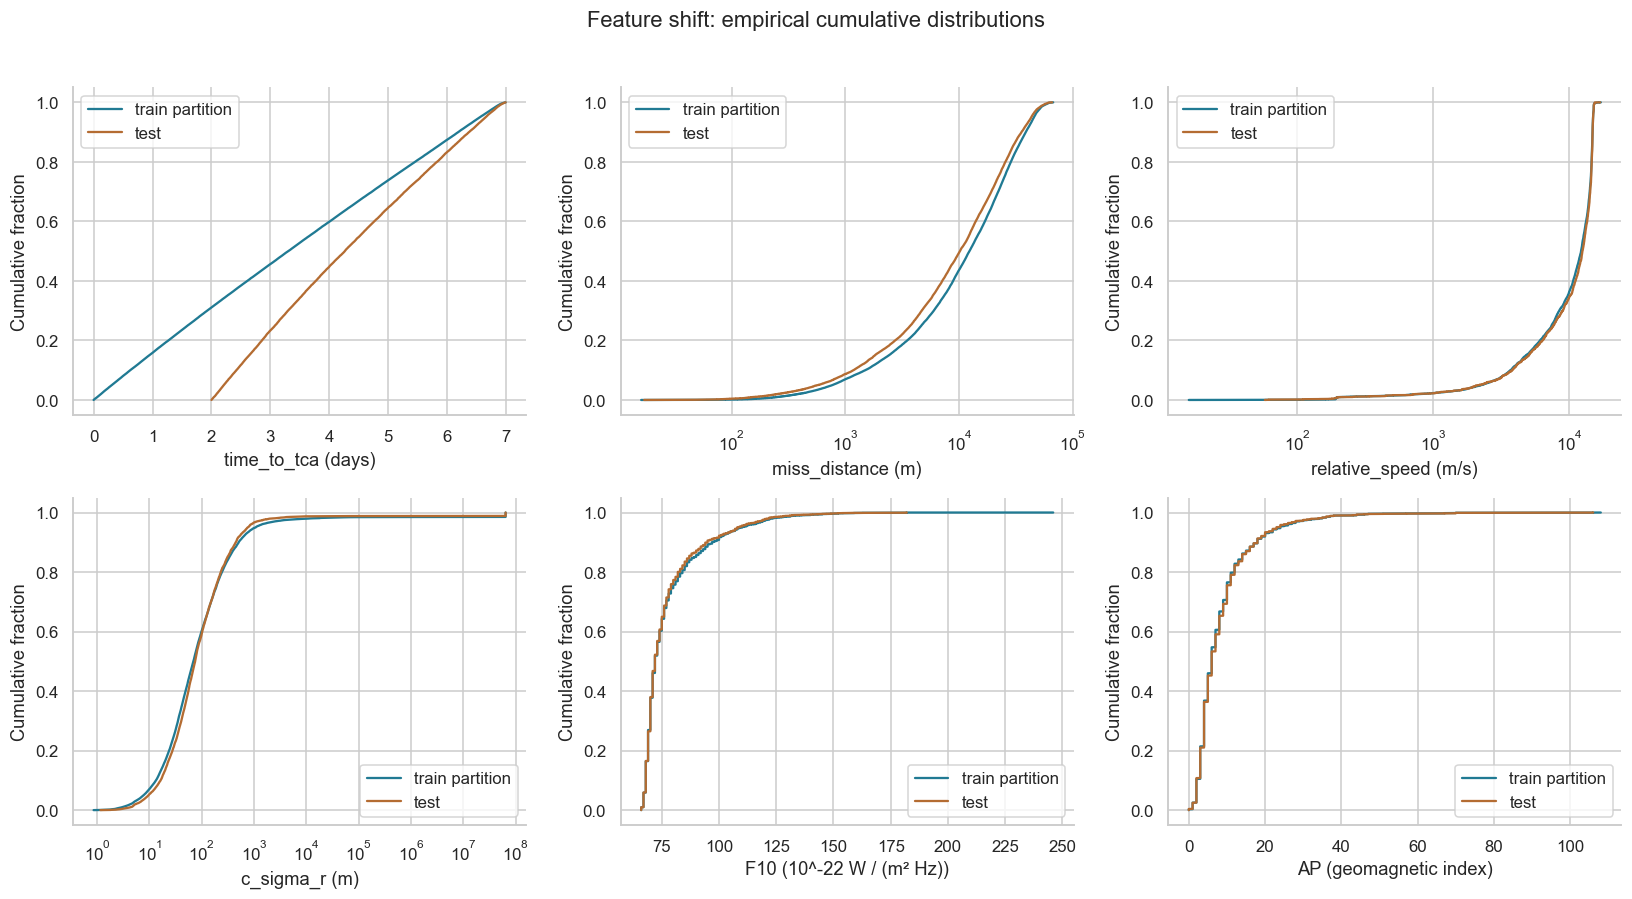

In [11]:
shift_rows = []
for col in NUMERIC:
    a = eda[col].replace([np.inf, -np.inf], np.nan)
    b = test[col].replace([np.inf, -np.inf], np.nan)
    shift_rows.append({'feature': col, 'train_missing_pct': 100 * a.isna().mean(),
        'test_missing_pct': 100 * b.isna().mean(), 'train_p05': a.quantile(.05),
        'test_p05': b.quantile(.05), 'train_median': a.median(), 'test_median': b.median(),
        'train_p95': a.quantile(.95), 'test_p95': b.quantile(.95)})
shift_table = pd.DataFrame(shift_rows)
display(shift_table)
category_shift = pd.concat({'train_partition': eda.c_object_type.fillna('(missing)').value_counts(normalize=True),
    'test': test.c_object_type.fillna('(missing)').value_counts(normalize=True)}, axis=1).fillna(0) * 100
unseen_categories = sorted(set(test.c_object_type.dropna()) - set(eda.c_object_type.dropna()))
display(category_shift.rename_axis('object_type'))
print('Categories in test but absent from analysis partition:', unseen_categories)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ['time_to_tca', 'miss_distance', 'relative_speed', 'c_sigma_r', 'F10', 'AP']):
    for label, frame, color in [('train partition', eda, '#207a93'), ('test', test, '#b46c32')]:
        values = np.sort(frame.loc[np.isfinite(frame[col]), col].to_numpy())
        ax.plot(values, np.arange(1, len(values)+1)/len(values), label=label, color=color)
    if col in ['miss_distance', 'relative_speed', 'c_sigma_r']:
        ax.set_xscale('symlog', linthresh=1)
    ax.set(xlabel=f'{col} ({UNITS[col]})', ylabel='Cumulative fraction'); ax.legend()
fig.suptitle('Feature shift: empirical cumulative distributions', y=1.02)
fig.tight_layout(); plt.show()

### Exact and approximate overlap

Exact matches use all 12 permitted predictors (excluding ID and target). Approximate candidates share object type and rounded telemetry: time to TCA to 0.01 day, miss distance and each relative-position component to 10 m, speed to 10 m/s. Missing/nonfinite fingerprint inputs are excluded.

This inexpensive rounded-bucket screen can miss nearby rows across bucket boundaries and can match unrelated rows. It is **not** a nearest-neighbor search or proof of shared event identity. Investigate candidates before changing the supplied train/test separation.

In [12]:
def exact_telemetry_hash(frame):
    normalized = frame[FEATURES].copy()
    for col in NUMERIC:
        normalized[col] = normalized[col].astype('float64')
    normalized['c_object_type'] = normalized.c_object_type.astype('string').fillna('<missing>')
    return pd.util.hash_pandas_object(normalized, index=False)

train_hash = exact_telemetry_hash(train_telemetry)
test_hash = exact_telemetry_hash(test)
exact_mask = test_hash.isin(set(train_hash))
ROUNDING = {'time_to_tca': .01, 'miss_distance': 10., 'relative_speed': 10.,
            'relative_position_r': 10., 'relative_position_t': 10., 'relative_position_n': 10.}
def approximate_fingerprints(frame):
    valid = np.isfinite(frame[list(ROUNDING)]).all(axis=1) & frame.c_object_type.notna()
    rounded = frame.loc[valid, list(ROUNDING)].div(pd.Series(ROUNDING)).round().astype('int64')
    rounded['c_object_type'] = frame.loc[valid, 'c_object_type'].astype('string')
    rounded['fingerprint'] = pd.util.hash_pandas_object(rounded, index=False)
    return frame.loc[valid, ['event_key', 'row_id']].join(rounded.fingerprint)

train_fingerprints = approximate_fingerprints(train_telemetry)
test_fingerprints = approximate_fingerprints(test)
approx_mask = test_fingerprints.fingerprint.isin(set(train_fingerprints.fingerprint))
overlap_summary = pd.Series({
    'overlapping numeric event ID values': len(set(train_telemetry.event_id) & set(test.event_id)),
    'shared source-qualified event keys': len(set(train_telemetry.event_key) & set(test.event_key)),
    'test rows with exact permitted-telemetry hash match': int(exact_mask.sum()),
    'test events with exact permitted-telemetry hash match': test.loc[exact_mask, 'event_id'].nunique(),
    'test rows with approximate fingerprint match': int(approx_mask.sum()),
    'test rows excluded from approximate screen': len(test) - len(test_fingerprints),
}, name='count')
display(overlap_summary.to_frame())
# Display bounded candidates; avoid an unbounded many-to-many merge.
matched_test = test_fingerprints.loc[approx_mask].head(10)
matched_train = train_fingerprints.drop_duplicates('fingerprint', keep='first')
candidate_pairs = matched_test.merge(matched_train, on='fingerprint', suffixes=('_test', '_train'))
if candidate_pairs.empty:
    print('No approximate candidates under this screen. This does not prove encounters are independent.')
else:
    display(candidate_pairs.drop(columns='fingerprint'))
    print('Candidate matches need manual investigation; no IDs are joined or rows automatically removed.')

,count
overlapping numeric event ID values,2167
shared source-qualified event keys,0
test rows with exact permitted-telemetry hash match,0
test events with exact permitted-telemetry hash match,0
test rows with approximate fingerprint match,0
test rows excluded from approximate screen,0


No approximate candidates under this screen. This does not prove encounters are independent.


## 7. Checks and modeling handoff

These checks protect the interpretation of the notebook: no test target, disjoint event partitions, correct unit conversions, boundary behavior, and event deduplication. They do not validate any prediction model.

The next stage should reuse the saved split, fit preprocessing on the training partition only, compare a median-target baseline with a modest tree model, and reserve the holdout for a single evaluation after selection. Keep sparse object categories, missingness, uncertainty extremes, the label floor, and near-threshold cases visible in error analysis.

In [13]:
assert 'risk' not in test and 'risk' not in train_telemetry
assert len(FEATURES) == 12 and 'event_id' not in FEATURES and 'risk' not in FEATURES
assert set(eda.event_id).isdisjoint(partitions['validation'] | partitions['holdout'])
assert np.isfinite(eda.risk).all() and eda.risk.le(0).all() and eda.time_to_tca.ge(0).all()
assert set(eda.event_key).isdisjoint(set(test.event_key))
assert latest.event_key.is_unique
assert len(latest) == eda.event_key.nunique()
assert np.isclose(24 * 1.0, 24) and np.isclose(1000 / 1000, 1)
assert np.allclose(10.0 ** np.array([-6., -4.]), [1e-6, 1e-4])
assert risk_tier([-7, -7, -7, -6, -4, -9, np.nan, np.nan, -4],
                 [5001, 5000, 1000, 6000, 6000, 999, 6000, 999, np.nan]).tolist() == [
    'safe', 'elevated', 'elevated', 'elevated', 'critical', 'critical', 'needs_review', 'critical', 'critical']
fixture = pd.DataFrame({'event_key': ['train:1','train:1','train:1','test:1','test:1'],
                        'time_to_tca': [2.,1.,1.,-1.,.5], 'row_id': [0,1,2,0,1]})
fixture_latest = latest_messages(fixture).set_index('event_key')
assert fixture_latest.loc['train:1', 'row_id'] == 2
assert fixture_latest.loc['test:1', 'row_id'] == 1
assert file_sha256(SPLIT_PATH) == manifest['split_sha256']
print('PASS: feature restrictions, target isolation, split integrity, thresholds, units, and latest-event selection.')

PASS: feature restrictions, target isolation, split integrity, thresholds, units, and latest-event selection.


In [14]:
def table_text(frame):
    return '```text\n' + frame.to_string() + '\n```'

critical_rows = int(eda.risk.ge(-4).sum())
combined_rows = int(eda.risk_tier.eq('critical').sum())
summary = f"""# EDA findings — satellite collision avoidance

Generated by `notebooks/01_eda.ipynb` from the supplied files. No model has been trained.

## Analysis boundary and reproducibility

- Detailed EDA: **{len(eda):,} eligible rows / {eda.event_id.nunique():,} events** in the 70% training partition.
- Seed: {SEED}. Events, not rows, are split. Validation and holdout labels are not explored beyond eligibility/stratification.
- Earlier repository-level inspection exposed aggregate full-training counts/ranges; this is disclosed rather than claiming a completely untouched dataset.
- Test `risk` is never loaded. Test telemetry is compared descriptively, not used to tune preprocessing.
- Training SHA-256: `{HASHES['train']}`.
- Test SHA-256: `{HASHES['test']}`.
- Split SHA-256: `{manifest['split_sha256']}`. Reuse `artifacts/event_splits.csv` and its manifest for modeling.

{table_text(split_sizes.loc[['train', 'validation', 'holdout']])}

## Measured findings

- Pc-critical training-partition messages: **{critical_rows:,} ({100*critical_rows/len(eda):.3f}%)**.
- Combined-rule critical messages: **{combined_rows:,} ({100*combined_rows/len(eda):.3f}%)**. Distance-driven positives must not conceal weak Pc detection.
- Observed target floor `-30`: **{floor_count:,} rows ({100*floor_count/len(eda):.2f}%)**. Whether this represents clipping/censoring needs provenance confirmation.
- Test messages within 24 hours: **{int(test.time_to_tca.between(0,1).sum()):,}**. These files cannot supply a populated actual next-day alert view.
- Test object categories unseen in the analysis partition: **{unseen_categories or 'none'}**.

### Eligibility audit (full training metadata and target validity only)
{table_text(eligibility.to_frame())}

### Missingness and validity (training partition)
{table_text(quality)}

### Risk counts: messages versus latest messages per event
{table_text(tier_counts)}

### Critical trigger decomposition
{table_text(trigger_counts.to_frame())}

### Extreme sigmas — inspection flags, not deletion rules
{table_text(sigma_audit)}

### Geometry consistency: absolute norm/distance discrepancy, metres
{table_text(geometry_summary.to_frame())}

### Duplicates and tied updates (training partition)
{table_text(duplicate_summary.to_frame())}

### Source overlap screen (all training telemetry versus test telemetry)
{table_text(overlap_summary.to_frame())}

Numeric ID overlap does not establish shared encounters. Exact comparisons are hash matches on permitted predictors, not full original rows. Approximate matches use rounded telemetry buckets, can have false positives and false negatives, and do not establish identity. No cross-source ID joins or automatic deletions were performed.

## Proposed modeling decisions — to validate, not fitted here

1. Reuse the frozen event split. Train on eligible prospective rows; retain original indices for exports.
2. Use only the 12 permitted predictors. Keep IDs as metadata and `risk` solely as the training target.
3. Fit numeric median imputation with missingness indicators and unknown-safe category encoding on training data only. Do not learn transforms from test telemetry.
4. Preserve extreme sigma flags. Investigate repeated extremes with the dataset provenance before deciding to mask or clip them. Any learned threshold belongs inside training preprocessing.
5. Compare a median-log-risk baseline with a modest HistGradientBoostingRegressor. Validate any nonnegative-feature log transforms before selecting them.
6. Report Pc-only critical precision/recall/F2/PR-AUC separately from combined distance/Pc tiers, plus regression errors and event-level false alarms.
7. Examine target-floor behavior and errors near -6 and -4, by object type, time band, and missingness. Do not claim physical Pc calibration from label reconstruction.
8. Confirm whether organizers score contemporaneous row risk or final risk per event before training the final submission model.

## Limits and next actions

- No accuracy or generalization claim can be made from this EDA; no model has been fitted.
- Correlations include repeated messages and are descriptive, not causal.
- R/T/N values describe updated encounter geometry at TCA, not true flight trajectories.
- Temporal distributions differ between supplied sources; no common wall-clock date is available for a real fleet forecast.
- Preserve the holdout for one final evaluation after model selection. Investigate overlap candidates before claiming independent unseen encounters.
- The challenge thresholds implement the supplied brief, not certification against a named NASA/ESA standard.

## Environment

Python {platform.python_version()}; dependencies: `{json.dumps(VERSIONS, sort_keys=True)}`.

References: [ESA data dictionary](https://kelvins.esa.int/collision-avoidance-challenge/data/), [original ESA task](https://kelvins.esa.int/collision-avoidance-challenge/challenge/), and the repository roadmap. The notebook defaults to the hackathon's row-prediction interpretation.
"""
(REPORTS / 'eda_summary.md').write_text(summary)
display(Markdown(f"""### Completed EDA handoff
- Analysis rows: **{len(eda):,}** across **{eda.event_id.nunique():,} training events**.
- Pc-critical rows: **{critical_rows:,} ({100*critical_rows/len(eda):.3f}%)**; combined-critical rows: **{combined_rows:,}**.
- Test rows in the next 24-hour interval: **{int(test.time_to_tca.between(0,1).sum()):,}**.
- Written: `reports/eda_summary.md`, `artifacts/event_splits.csv`, `artifacts/eda_manifest.json`.
- **Next step:** review these findings before fitting the baseline. Validation and holdout remain reserved."""))

### Completed EDA handoff
- Analysis rows: **113,195** across **9,200 training events**.
- Pc-critical rows: **503 (0.444%)**; combined-critical rows: **8,117**.
- Test rows in the next 24-hour interval: **0**.
- Written: `reports/eda_summary.md`, `artifacts/event_splits.csv`, `artifacts/eda_manifest.json`.
- **Next step:** review these findings before fitting the baseline. Validation and holdout remain reserved.